Equations of linear motion:
$$v = u + at \tag{1}$$
$$s = ut + \frac{1}{2}at^2 \tag{2}$$
$$s = \frac{1}{2}(v + u)t \tag{3}$$
$$v^2 = u^2 +2as \tag{4}$$
$$s = vt - \frac{1}{2}at^2 \tag{5}$$

Where the symbols:
- displacement $s$
- initial velocity $u$
- final velocity $v$
- acceleration $a$
- time $t$

A throw consists of an initial velocity vector $V$. In 2D the vector is defined by an angle alpha to the horizon, so that the vertical and horizontal componets $V_y$ and $V_x$ are:
$$V_y = V \sin \alpha$$
$$V_x = V \cos \alpha$$

The position in the vertical at time $t$ is found by considering the initial velocity $v = V_y(0)$ and the acceleration due to gravity $g$:
$$V_y(t) = V_y(0) - gt$$
If we makes some approximations:
* object is released from ground level
* no air resistance, no wind


Then we can say the velocity when the object lands (at time $t=T$) is equal in magnitude to the initial velocity $\vert V_y(T) \vert= \vert V_y(0) \vert$, and we can find the time of flight $T$ from equation (1) above:
$$-V_y(0) = V_y(0) - gT$$
$$T = \frac{2V_y(0)}{g}$$

Usually we then want to find the distance $s$ that the object will travel in this time $T$, which can be found from equation (2), assuming no wind or air resistance (i.e. zero acceleration $a=0$):
$$s = V_x(0)T$$
$$s = V \cos \alpha T$$
$$= \frac{2}{g} V^2 \cos \alpha \sin \alpha$$
$$= \frac{1}{g} V^2 \sin 2 \alpha$$

If we would decide a particular distance of interest $S$ and assume a value for $V$ (ChatGPT suggests a range of 6m/s to 9m/S for an 8 year old of 135cm height), we can determine an reference value for the angle $\alpha$:
$$\sin 2 \alpha = \frac{Sg}{V^2}$$
$$\alpha = 0.5 \arcsin \left( \frac{Sg}{V^2} \right)$$

The peak height $h$ reached for a given initial velocity is found from equation (3) at time $t=\frac{T}{2}$:
$$ h = \frac{V\sin \alpha}{2} \frac{T}{2}$$
$$ = \frac{V\sin \alpha}{2} \frac{V\sin \alpha}{g}$$
$$ = \frac{V^2 \sin^2 \alpha}{2g}$$

/tmp/ipykernel_188/2160935037.py:4: RuntimeWarning: invalid value encountered in arcsin
  alpha = 0.5 * np.arcsin((S*g)/V**2)


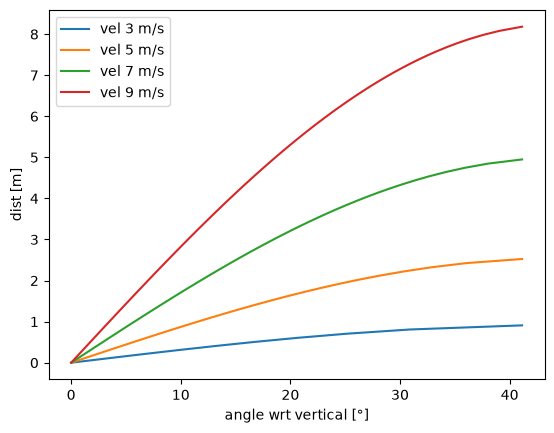

In [45]:
import numpy as np
import matplotlib.pyplot as plt
def get_alpha(S, V, g=9.81):
    alpha = 0.5 * np.arcsin((S*g)/V**2)
    return np.degrees(alpha)

V = [3,5,7,9]
S = np.linspace(0,10,100)

for v in V:
    a = get_alpha(S,v)
    plt.plot(a, S, '-', label=f'vel {v} m/s')

#plt.plot([135, 135], [3, 10], ':', label='max range')

plt.ylabel('dist [m]')
plt.xlabel('angle wrt vertical [°]')
plt.legend()
plt.show()

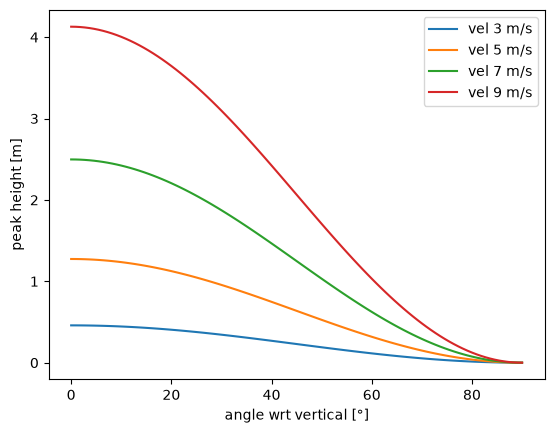

In [6]:
import numpy as np
import matplotlib.pyplot as plt
def get_height(alpha, V, g=9.81):
    return ((V * np.sin(np.radians(alpha)))**2)/(2*g)

V = [3,5,7,9]
a = np.linspace(0,90,100)


for v in V:
    h = get_height(90-a, v)
    plt.plot(a, h, '-', label=f'vel {v} m/s')

plt.xlabel('angle wrt vertical [°]')
plt.ylabel('peak height [m]')
plt.legend()
plt.show()

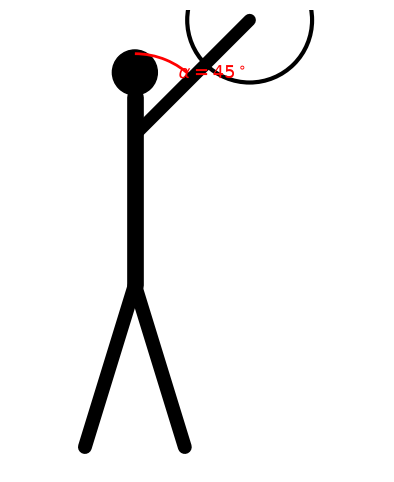

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Arc


def draw_gymnast(alpha_deg):
    fig, ax = plt.subplots(figsize=(5, 6))

    # Head
    ax.add_patch(Circle((0, 3.2), 0.18, color="black"))

    # Torso
    ax.plot(
        [0, 0], [1.5, 3.0],
        color="black", linewidth=12,
        solid_capstyle="round"
    )

    # Legs
    ax.plot(
        [0, -0.4], [1.5, 0.2],
        color="black", linewidth=10,
        solid_capstyle="round"
    )
    ax.plot(
        [0, 0.4], [1.5, 0.2],
        color="black", linewidth=10,
        solid_capstyle="round"
    )

    # Shoulder position
    shoulder = np.array([0.0, 2.7])
    arm_length = 1.3

    # Alpha = 0 degrees means vertically upwards.
    alpha = np.radians(alpha_deg)

    # Calculate hand position
    hand = shoulder + arm_length * np.array([
        np.sin(alpha),
        np.cos(alpha)
    ])

    # Throwing arm
    ax.plot(
        [shoulder[0], hand[0]],
        [shoulder[1], hand[1]],
        color="black", linewidth=9,
        solid_capstyle="round"
    )

    # Hoop at the hand
    ax.add_patch(
        Circle(
            hand, 0.5,
            fill=False,
            edgecolor="black",
            linewidth=3
        )
    )

    # Angle arc measured clockwise from vertical upwards
    arc_radius = 0.65

    ax.add_patch(
        Arc(
            shoulder,
            2 * arc_radius,
            2 * arc_radius,
            theta1=90 - alpha_deg,
            theta2=90,
            color="red",
            linewidth=2
        )
    )

    # Angle label
    ax.text(
        shoulder[0] + 0.35,
        shoulder[1] + 0.45,
        rf"$\alpha = {alpha_deg}^\circ$",
        fontsize=13,
        color="red"
    )

    # Formatting
    ax.set_aspect("equal")
    ax.set_xlim(-1, 2)
    ax.set_ylim(0, 3.7)
    ax.axis("off")

    plt.show()


# Example
draw_gymnast(45)

Note: you may need to restart the kernel to use updated packages.


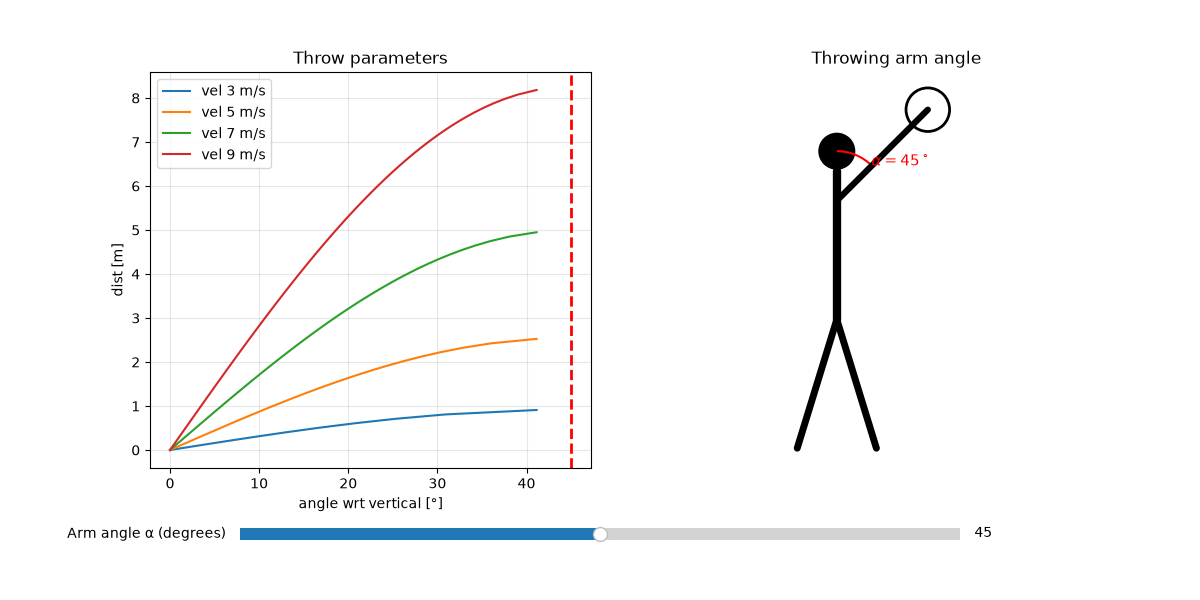

In [49]:
%pip install ipympl
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Arc
from matplotlib.widgets import Slider


# ==================================================
# 1. Calculate angle from distance and velocity
# ==================================================

def get_alpha(S, V, g=9.81):
    alpha = 0.5 * np.arcsin((S * g) / V**2)
    return np.degrees(alpha)


# ==================================================
# 2. Figure and subplots
# ==================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(12, 6),
    gridspec_kw={'width_ratios': [1.2, 1]}
)

# Reserve space for the slider
plt.subplots_adjust(bottom=0.22, wspace=0.30)


# ==================================================
# 3. Left plot: distance vs angle
# ==================================================

V = [3, 5, 7, 9]
S = np.linspace(0, 10, 100)

for v in V:
    # Keep only values in the real domain of arcsin
    valid = (S * 9.81 / v**2) <= 1

    a = get_alpha(S[valid], v)

    ax1.plot(
        a, S[valid],
        '-',
        label=f'vel {v} m/s'
    )

ax1.set_ylabel('dist [m]')
ax1.set_xlabel('angle wrt vertical [°]')
ax1.set_title('Throw parameters')
ax1.legend()
ax1.grid(True, alpha=0.3)


# Initial selected angle
initial_alpha = 45

# Vertical line representing the selected angle
angle_line = ax1.axvline(
    initial_alpha,
    color='red',
    linestyle='--',
    linewidth=2,
    label='Selected angle'
)


# ==================================================
# 4. Right plot: gymnast illustration
# ==================================================

# Scale the entire gymnast to half size
scale = 0.5

ax2.set_title('Throwing arm angle')
ax2.set_aspect('equal')
ax2.set_xlim(-0.6, 1.2)
ax2.set_ylim(0, 2.0)
ax2.axis('off')


# ------------------------------
# Head
# ------------------------------

ax2.add_patch(
    Circle(
        (0, 3.2 * scale),
        0.18 * scale,
        color='black'
    )
)


# ------------------------------
# Torso
# ------------------------------

ax2.plot(
    [0, 0],
    [1.5 * scale, 3.0 * scale],
    color='black',
    linewidth=12 * scale,
    solid_capstyle='round'
)


# ------------------------------
# Legs
# ------------------------------

ax2.plot(
    [0, -0.4 * scale],
    [1.5 * scale, 0.2 * scale],
    color='black',
    linewidth=10 * scale,
    solid_capstyle='round'
)

ax2.plot(
    [0, 0.4 * scale],
    [1.5 * scale, 0.2 * scale],
    color='black',
    linewidth=10 * scale,
    solid_capstyle='round'
)


# ------------------------------
# Shoulder and arm
# ------------------------------

shoulder = np.array([0.0, 2.7 * scale])
arm_length = 1.3 * scale

arm_line, = ax2.plot(
    [],
    [],
    color='black',
    linewidth=9 * scale,
    solid_capstyle='round'
)


# ------------------------------
# Hoop
# ------------------------------

hoop = Circle(
    (0, 0),
    0.22 * scale,
    fill=False,
    edgecolor='black',
    linewidth=2
)

ax2.add_patch(hoop)


# ------------------------------
# Angle arc
# ------------------------------

angle_arc = Arc(
    shoulder,
    1.0 * scale,
    1.0 * scale,
    theta1=45,
    theta2=90,
    color='red',
    linewidth=1.5
)

ax2.add_patch(angle_arc)


# ------------------------------
# Angle label
# ------------------------------

angle_text = ax2.text(
    0.35 * scale,
    3.05 * scale,
    '',
    fontsize=11,
    color='red'
)


# ==================================================
# 5. Interactive slider
# ==================================================

slider_ax = fig.add_axes([0.20, 0.09, 0.60, 0.04])

alpha_slider = Slider(
    ax=slider_ax,
    label='Arm angle α (degrees)',
    valmin=0,
    valmax=90,
    valinit=initial_alpha,
    valstep=1
)


# ==================================================
# 6. Update function
# ==================================================

def update(alpha_deg):

    alpha = np.radians(alpha_deg)

    # alpha = 0°: arm points vertically upwards
    # alpha = 90°: arm points horizontally outwards
    hand = shoulder + arm_length * np.array([
        np.sin(alpha),
        np.cos(alpha)
    ])

    # Update arm position
    arm_line.set_data(
        [shoulder[0], hand[0]],
        [shoulder[1], hand[1]]
    )

    # Update hoop position
    hoop.center = hand

    # Update angle arc
    angle_arc.theta1 = 90 - alpha_deg
    angle_arc.theta2 = 90

    # Update angle label
    angle_text.set_text(
        rf'$\alpha = {alpha_deg:.0f}^\circ$'
    )

    # Update vertical line on the left plot
    angle_line.set_xdata([alpha_deg, alpha_deg])

    # Redraw
    fig.canvas.draw_idle()


# ==================================================
# 7. Connect slider and initialise
# ==================================================

alpha_slider.on_changed(update)

update(initial_alpha)

plt.show()

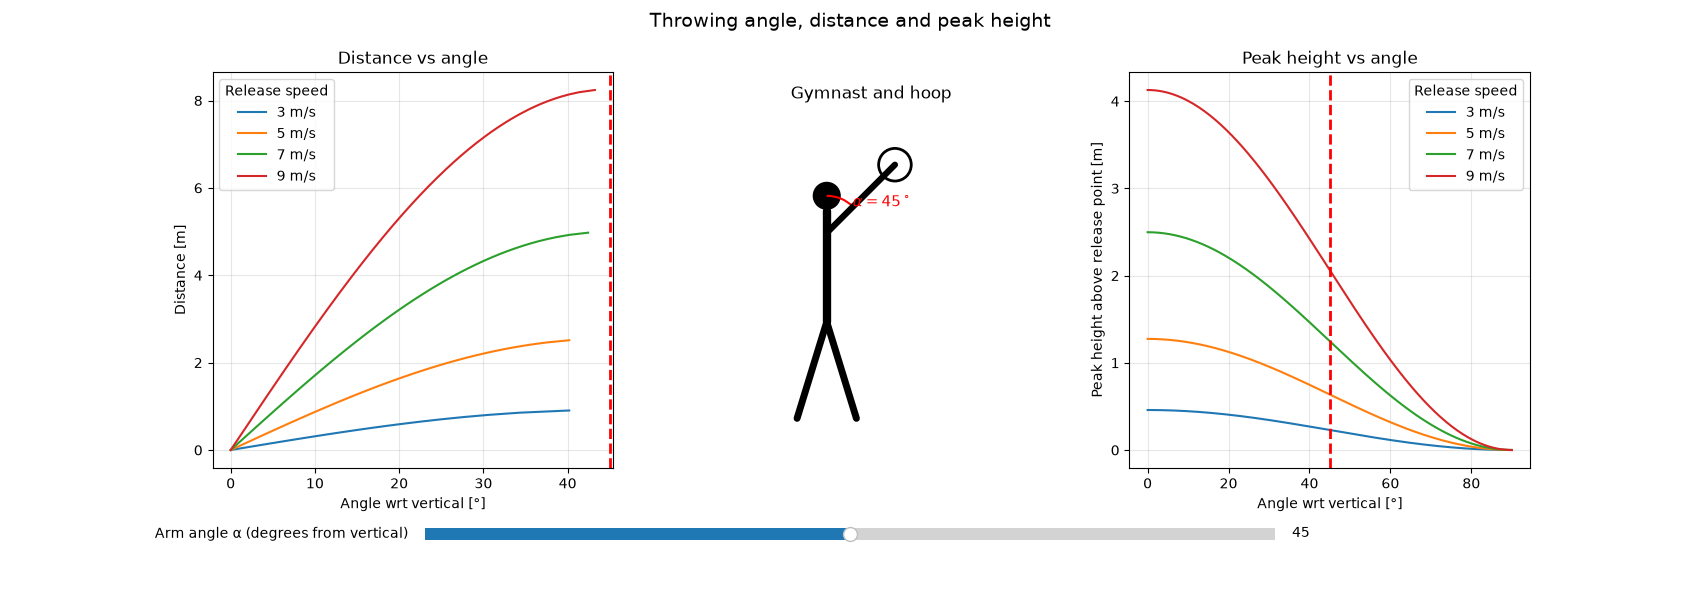

In [8]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Arc
from matplotlib.widgets import Slider


# --------------------------------------------------
# Functions
# --------------------------------------------------

def get_alpha(S, V, g=9.81):
    """Calculate the angle from the vertical, in degrees."""
    return np.degrees(0.5 * np.arcsin((S * g) / V**2))


def get_height(alpha, V, g=9.81):
    """
    Calculate peak height above the release point.

    alpha is the launch angle measured from the horizontal,
    in degrees.
    """
    return ((V * np.sin(np.radians(alpha)))**2) / (2 * g)


# --------------------------------------------------
# Figure and layout
# --------------------------------------------------

fig, (ax1, ax2, ax3) = plt.subplots(
    1, 3,
    figsize=(17, 6),
    gridspec_kw={'width_ratios': [1.2, 0.8, 1.2]}
)

plt.subplots_adjust(
    bottom=0.22,
    top=0.88,
    wspace=0.35
)


# --------------------------------------------------
# GRAPH 1: Distance versus angle
# --------------------------------------------------

V = [3, 5, 7, 9]
S = np.linspace(0, 10, 200)

for v in V:
    # Keep only values within the arcsin domain
    valid = (S * 9.81 / v**2) <= 1

    a = get_alpha(S[valid], v)
    ax1.plot(a, S[valid], '-', label=f'{v} m/s')

ax1.set_xlabel('Angle wrt vertical [°]')
ax1.set_ylabel('Distance [m]')
ax1.set_title('Distance vs angle')
ax1.legend(title='Release speed')
ax1.grid(True, alpha=0.3)

initial_alpha = 45

# Interactive angle indicator
angle_line1 = ax1.axvline(
    initial_alpha,
    color='red',
    linestyle='--',
    linewidth=2
)


# --------------------------------------------------
# GRAPH 2: Gymnast silhouette and hoop
# --------------------------------------------------

scale = 0.5

ax2.set_title('Gymnast and hoop')
ax2.set_aspect('equal')
ax2.set_xlim(-0.6, 1.2)
ax2.set_ylim(0, 2.2)
ax2.axis('off')

# Head
ax2.add_patch(
    Circle((0, 3.2 * scale), 0.18 * scale, color='black')
)

# Body
ax2.plot(
    [0, 0],
    [1.5 * scale, 3.0 * scale],
    color='black',
    linewidth=12 * scale,
    solid_capstyle='round'
)

# Legs
ax2.plot(
    [0, -0.4 * scale],
    [1.5 * scale, 0.2 * scale],
    color='black',
    linewidth=10 * scale,
    solid_capstyle='round'
)

ax2.plot(
    [0, 0.4 * scale],
    [1.5 * scale, 0.2 * scale],
    color='black',
    linewidth=10 * scale,
    solid_capstyle='round'
)

# Shoulder and arm
shoulder = np.array([0.0, 2.7 * scale])
arm_length = 1.3 * scale

arm_line, = ax2.plot(
    [], [],
    color='black',
    linewidth=9 * scale,
    solid_capstyle='round'
)

# Hoop
hoop = Circle(
    (0, 0),
    0.22 * scale,
    fill=False,
    edgecolor='black',
    linewidth=2
)
ax2.add_patch(hoop)

# Angle arc
angle_arc = Arc(
    shoulder,
    1.0 * scale,
    1.0 * scale,
    theta1=45,
    theta2=90,
    color='red',
    linewidth=1.5
)
ax2.add_patch(angle_arc)

# Angle label
angle_text = ax2.text(
    0.35 * scale,
    3.05 * scale,
    '',
    fontsize=11,
    color='red'
)


# --------------------------------------------------
# GRAPH 3: Peak height versus angle
# --------------------------------------------------

a = np.linspace(0, 90, 200)

for v in V:
    # alpha is measured from the vertical.
    # Therefore, the launch angle from the horizontal is 90 - a.
    h = get_height(90 - a, v)

    ax3.plot(a, h, '-', label=f'{v} m/s')

ax3.set_xlabel('Angle wrt vertical [°]')
ax3.set_ylabel('Peak height above release point [m]')
ax3.set_title('Peak height vs angle')
ax3.legend(title='Release speed')
ax3.grid(True, alpha=0.3)

# Interactive angle indicator
angle_line3 = ax3.axvline(
    initial_alpha,
    color='red',
    linestyle='--',
    linewidth=2
)


# --------------------------------------------------
# INTERACTIVE SLIDER
# --------------------------------------------------

slider_ax = fig.add_axes([0.25, 0.09, 0.50, 0.04])

alpha_slider = Slider(
    slider_ax,
    label='Arm angle α (degrees from vertical)',
    valmin=0,
    valmax=90,
    valinit=initial_alpha,
    valstep=1
)


# --------------------------------------------------
# UPDATE ALL THREE PANELS
# --------------------------------------------------

def update(alpha_deg):
    alpha = np.radians(alpha_deg)

    # Calculate hand position:
    # 0° = arm vertically upwards
    # 90° = arm horizontally outwards
    hand = shoulder + arm_length * np.array([
        np.sin(alpha),
        np.cos(alpha)
    ])

    # Update arm
    arm_line.set_data(
        [shoulder[0], hand[0]],
        [shoulder[1], hand[1]]
    )

    # Move hoop to the hand
    hoop.center = hand

    # Update angle arc
    angle_arc.theta1 = 90 - alpha_deg
    angle_arc.theta2 = 90

    # Update angle label
    angle_text.set_text(rf'$\alpha = {alpha_deg:.0f}^\circ$')

    # Move both graph indicators
    angle_line1.set_xdata([alpha_deg, alpha_deg])
    angle_line3.set_xdata([alpha_deg, alpha_deg])

    # Redraw
    fig.canvas.draw_idle()


# Connect slider and initialize
alpha_slider.on_changed(update)
update(initial_alpha)

fig.suptitle(
    'Throwing angle, distance and peak height',
    fontsize=14
)

plt.show()